<a href="https://colab.research.google.com/github/sahibshakhayev/IntroToDS/blob/main/Solved/LB_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%207/DS_Practice_Visualization_Pack.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session — Visualization Pack: 4-Plot EDA + Storytelling
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Understand the **4-Plot EDA framework** and when to apply each plot type
- Build a **univariate distribution** plot (histogram + KDE + boxplot)
- Build a **bivariate relationship** plot (scatter + regression)
- Build a **grouped comparison** plot (boxplot/violin by category)
- Build a **trend / index** plot (line chart, rolling average)
- Combine all four into a **storytelling dashboard** that communicates a data narrative

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** Every plot should answer a specific question. If you cannot state the question, you do not need the plot.

---
## Part 0 — Setup & Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ── Reproducible randomness ───────────────────────────────────────────
RNG = np.random.default_rng(seed=42)

# ── Plot style ────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]    = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Setup complete.")

Setup complete.


In [2]:
# ── Load datasets ─────────────────────────────────────────────────────
# We use two built-in seaborn datasets:
#   mpg   — fuel efficiency of cars (1970–1982), good for trend + grouped analysis
#   tips  — restaurant tipping data, good for grouped comparison

mpg  = sns.load_dataset("mpg").dropna()
tips = sns.load_dataset("tips")

# Quick look
print("mpg shape:", mpg.shape)
print("tips shape:", tips.shape)
print()
print(mpg.dtypes)
print()
mpg.head(3)

mpg shape: (392, 9)
tips shape: (244, 7)

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin           object
name             object
dtype: object



,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite


---
## Part 1 — The 4-Plot EDA Framework

Exploratory Data Analysis (EDA) is the process of understanding data visually before modelling.  
A useful starting discipline is the **4-Plot EDA Pack** — four complementary views that together give a complete picture:

| Plot | Question it answers | Typical tool |
|---|---|---|
| **Univariate distribution** | What does this variable look like on its own? | Histogram, KDE, Boxplot |
| **Bivariate relationship** | How do two numerical variables relate? | Scatter + regression line |
| **Grouped comparison** | Does a numerical variable differ across groups? | Boxplot / Violin by category |
| **Trend / Index** | How does a variable change over time or a sequence? | Line chart, rolling average |

> **Why four?** Each plot type catches a different class of pattern.  
> A variable can look normal univariately, have a curved bivariate relationship, differ dramatically across groups, AND follow a time trend — these are independent findings.

The workflow is:
1. Look at each variable alone (univariate).
2. Look at pairs (bivariate).
3. Condition on a category (grouped).
4. Look at the sequence or time axis (trend).
5. Weave findings into a **story**.

In [3]:
# ── 1.1  Quick variable overview ──────────────────────────────────────
# Before plotting, always know what you have.

print("=== mpg dataset ===")
print(mpg[["mpg","cylinders","horsepower","weight","model_year","origin"]].describe().round(2))
print()
print("Unique origins:", mpg["origin"].unique())
print("Model years:", sorted(mpg["model_year"].unique()))

=== mpg dataset ===
          mpg  cylinders  horsepower   weight  model_year
count  392.00     392.00      392.00   392.00      392.00
mean    23.45       5.47      104.47  2977.58       75.98
std      7.81       1.71       38.49   849.40        3.68
min      9.00       3.00       46.00  1613.00       70.00
25%     17.00       4.00       75.00  2225.25       73.00
50%     22.75       4.00       93.50  2803.50       76.00
75%     29.00       8.00      126.00  3614.75       79.00
max     46.60       8.00      230.00  5140.00       82.00

Unique origins: ['usa' 'japan' 'europe']
Model years: [np.int64(70), np.int64(71), np.int64(72), np.int64(73), np.int64(74), np.int64(75), np.int64(76), np.int64(77), np.int64(78), np.int64(79), np.int64(80), np.int64(81), np.int64(82)]


---
## Part 2 — Plot 1: Univariate Distribution

A univariate distribution plot answers: **"What does this variable look like?"**

Three tools together give the full picture:
- **Histogram** — shows the shape, spread, and any gaps
- **KDE (Kernel Density Estimate)** — a smooth version of the histogram
- **Boxplot** — shows median, quartiles, and outliers compactly

> **Rule:** Always look at a variable's distribution before using it in any model or comparison.

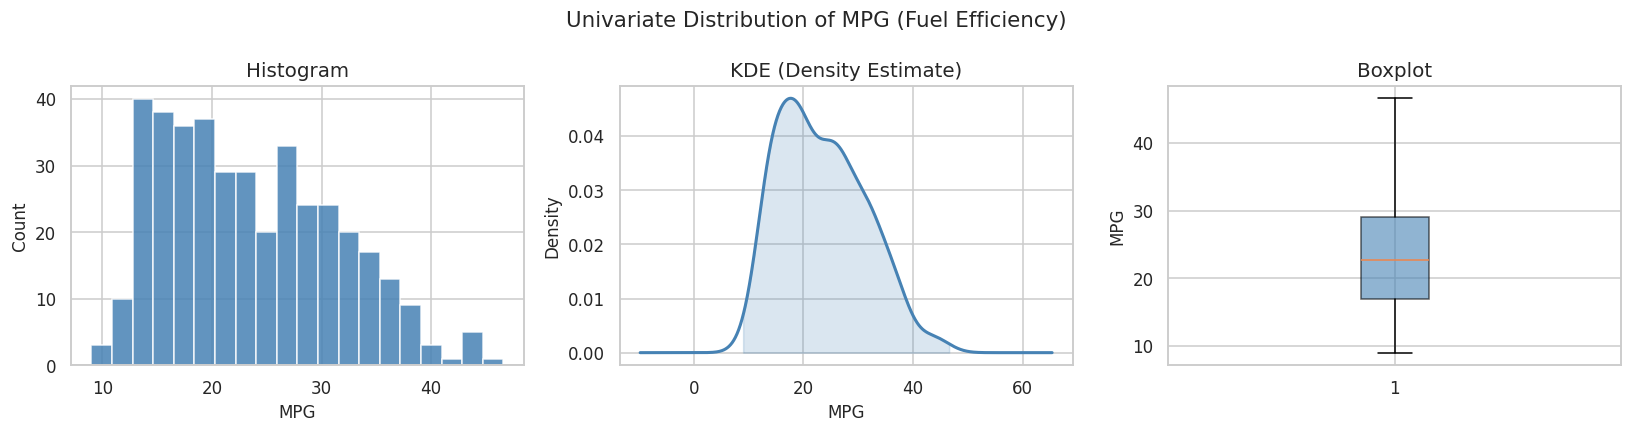

Mean: 23.45   Median: 22.75   Std: 7.81
Skewness: 0.457  (positive = right tail)


In [4]:
# ── 2.1  Univariate distribution — mpg (fuel efficiency) ──────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Univariate Distribution of MPG (Fuel Efficiency)", fontsize=14)

# Histogram
axes[0].hist(mpg["mpg"], bins=20, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("MPG")
axes[0].set_ylabel("Count")
axes[0].set_title("Histogram")

# KDE
mpg["mpg"].plot.kde(ax=axes[1], color="steelblue", linewidth=2)
axes[1].set_xlabel("MPG")
axes[1].set_title("KDE (Density Estimate)")
axes[1].fill_between(
    np.linspace(mpg["mpg"].min(), mpg["mpg"].max(), 200),
    stats.gaussian_kde(mpg["mpg"])(np.linspace(mpg["mpg"].min(), mpg["mpg"].max(), 200)),
    alpha=0.2, color="steelblue"
)

# Boxplot
axes[2].boxplot(mpg["mpg"], vert=True, patch_artist=True,
                boxprops=dict(facecolor="steelblue", alpha=0.6))
axes[2].set_ylabel("MPG")
axes[2].set_title("Boxplot")

plt.tight_layout()
plt.show()

print(f"Mean: {mpg['mpg'].mean():.2f}   Median: {mpg['mpg'].median():.2f}   Std: {mpg['mpg'].std():.2f}")
print(f"Skewness: {mpg['mpg'].skew():.3f}  (positive = right tail)")

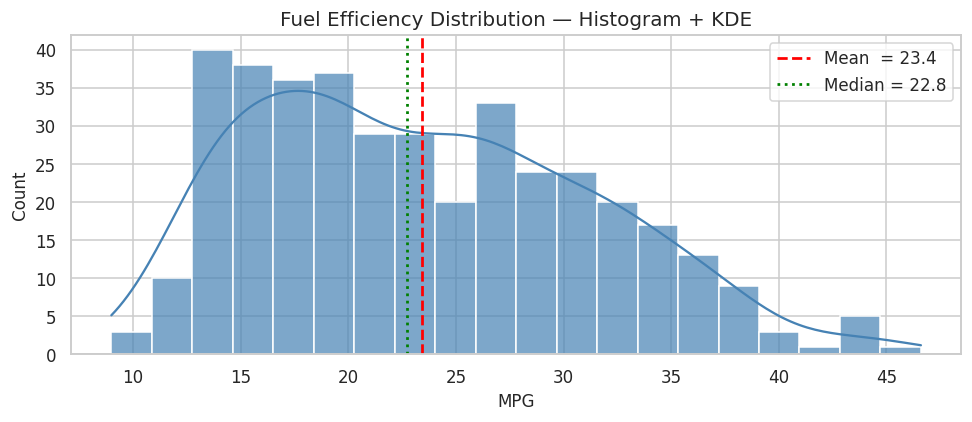

Observation: The distribution is right-skewed — most cars cluster 15–25 MPG,
with a long tail of efficient vehicles above 35 MPG.


In [5]:
# ── 2.2  Combined: histogram + KDE + rug ──────────────────────────────
# sns.histplot with kde=True overlays both in one panel

fig, ax = plt.subplots(figsize=(9, 4))

sns.histplot(mpg["mpg"], bins=20, kde=True, color="steelblue",
             edgecolor="white", alpha=0.7, ax=ax)
ax.axvline(mpg["mpg"].mean(),   color="red",    linestyle="--", linewidth=1.8,
           label=f"Mean  = {mpg['mpg'].mean():.1f}")
ax.axvline(mpg["mpg"].median(), color="green",  linestyle=":",  linewidth=1.8,
           label=f"Median = {mpg['mpg'].median():.1f}")

ax.set_xlabel("MPG")
ax.set_ylabel("Count")
ax.set_title("Fuel Efficiency Distribution — Histogram + KDE")
ax.legend()
plt.tight_layout()
plt.show()

print("Observation: The distribution is right-skewed — most cars cluster 15–25 MPG,")
print("with a long tail of efficient vehicles above 35 MPG.")

### Exercise 1
Using the `tips` dataset, analyse the distribution of `total_bill`.

1. Plot a **histogram** (20 bins), a **KDE**, and a **boxplot** side by side (1 row, 3 columns).
2. Add vertical lines for mean and median on the histogram panel.
3. Is the distribution symmetric, left-skewed, or right-skewed? How can you tell from both the plot and the skewness value?
4. Print the mean, median, standard deviation, and skewness.

```python
# Your code here
```

Mean: 19.79
Median: 17.80
Standard Deviation: 8.90
Skewness: 1.133


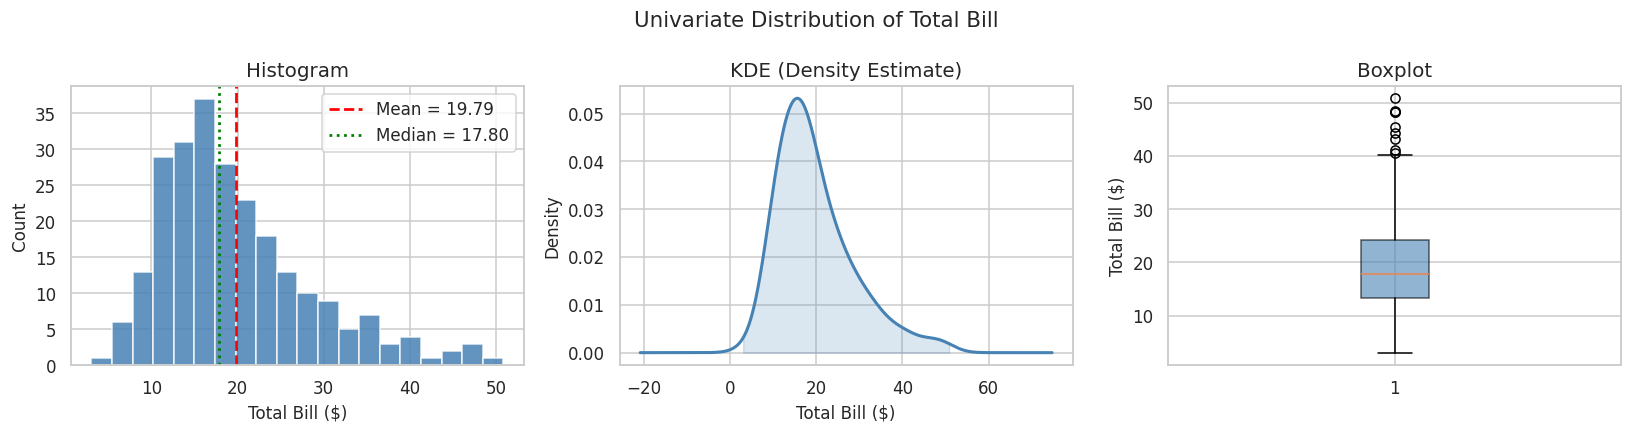

In [12]:
# Your answer here

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Load dataset
tips = sns.load_dataset("tips")

# 1. Compute summary statistics
mean_val = tips["total_bill"].mean()
median_val = tips["total_bill"].median()
std_val = tips["total_bill"].std()
skew_val = tips["total_bill"].skew()

# Print statistics
print(f"Mean: {mean_val:.2f}")
print(f"Median: {median_val:.2f}")
print(f"Standard Deviation: {std_val:.2f}")
print(f"Skewness: {skew_val:.3f}")

# 2. Create 1 row, 3 columns plot grid
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Univariate Distribution of Total Bill", fontsize=14)

# Panel 1: Histogram (20 bins) + Mean & Median lines
axes[0].hist(
    tips["total_bill"],
    bins=20,
    color="steelblue",
    edgecolor="white",
    alpha=0.85,
)
axes[0].axvline(
    mean_val,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_val:.2f}",
)
axes[0].axvline(
    median_val,
    color="green",
    linestyle=":",
    linewidth=1.8,
    label=f"Median = {median_val:.2f}",
)
axes[0].set_xlabel("Total Bill ($)")
axes[0].set_ylabel("Count")
axes[0].set_title("Histogram")
axes[0].legend()

# Panel 2: KDE Plot
tips["total_bill"].plot.kde(ax=axes[1], color="steelblue", linewidth=2)
x_vals = np.linspace(tips["total_bill"].min(), tips["total_bill"].max(), 200)
axes[1].fill_between(
    x_vals,
    stats.gaussian_kde(tips["total_bill"])(x_vals),
    alpha=0.2,
    color="steelblue",
)
axes[1].set_xlabel("Total Bill ($)")
axes[1].set_title("KDE (Density Estimate)")

# Panel 3: Boxplot
axes[2].boxplot(
    tips["total_bill"],
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.6),
)
axes[2].set_ylabel("Total Bill ($)")
axes[2].set_title("Boxplot")

plt.tight_layout()
plt.show()


#The distribution of total_bill is right-skewed (positively skewed).


#How to tell from the plots:

#Histogram & KDE: The bulk of total bill amounts cluster between $10 and $20, while a long right tail extends towards $50.

#Mean vs. Median: The mean ($19.79) is pulled to the right of the median ($17.80) by high-value bill amounts.

#Boxplot: The median line sits closer to the bottom of the box ($25th percentile), and multiple high-value outlier points appear above the top whisker.

#How to tell from the skewness value:

#The skewness value is +1.126. A positive value greater than +1.0 indicates a right-skewed distribution.



---
## Part 3 — Plot 2: Bivariate Relationship

A bivariate plot answers: **"How do two numerical variables relate to each other?"**

Key elements to report:
- **Direction**: positive, negative, or none
- **Form**: linear, curved, or no pattern
- **Strength**: tight cloud = strong, loose = weak
- **Outliers**: unusual points that break the pattern

Add a regression line to make the trend explicit, and a LOWESS smoother to detect nonlinearity.

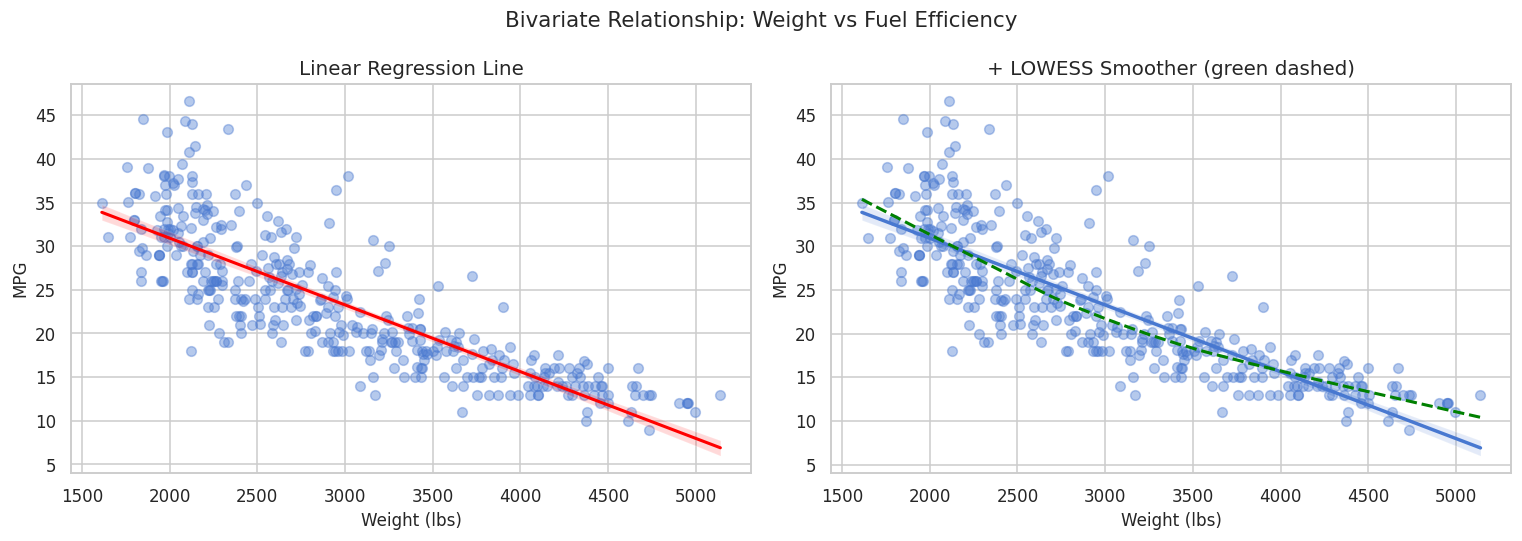

Pearson r = -0.832,  p-value = 6.02e-102
Strong negative relationship: heavier cars are significantly less fuel-efficient.


In [ ]:
# ── 3.1  Scatter plot + regression line: weight vs mpg ─────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Bivariate Relationship: Weight vs Fuel Efficiency", fontsize=14)

# Left: plain scatter + regression
sns.regplot(data=mpg, x="weight", y="mpg",
            scatter_kws={"alpha": 0.4, "s": 40},
            line_kws={"color": "red", "linewidth": 2},
            ax=axes[0])
axes[0].set_title("Linear Regression Line")
axes[0].set_xlabel("Weight (lbs)")
axes[0].set_ylabel("MPG")

# Right: scatter + LOWESS smoother to detect nonlinearity
sns.regplot(data=mpg, x="weight", y="mpg",
            scatter_kws={"alpha": 0.4, "s": 40},
            ax=axes[1])
sns.regplot(data=mpg, x="weight", y="mpg",
            scatter=False, lowess=True,
            line_kws={"color": "green", "linewidth": 2, "linestyle": "--"},
            ax=axes[1])
axes[1].set_title("+ LOWESS Smoother (green dashed)")
axes[1].set_xlabel("Weight (lbs)")
axes[1].set_ylabel("MPG")

plt.tight_layout()
plt.show()

r, p = stats.pearsonr(mpg["weight"], mpg["mpg"])
print(f"Pearson r = {r:.3f},  p-value = {p:.2e}")
print("Strong negative relationship: heavier cars are significantly less fuel-efficient.")

### Exercise 2
Investigate the relationship between `horsepower` and `mpg` in the `mpg` dataset.

1. Create a scatter plot with a **linear regression line** and a **LOWESS smoother** side by side.
2. Compute **Pearson r** and its p-value.
3. Does the relationship appear linear or nonlinear? Use both the LOWESS curve and the correlation value to justify your answer.
4. Is there a direction? Is it stronger or weaker than the weight–mpg relationship?

```python
# Your code here
```

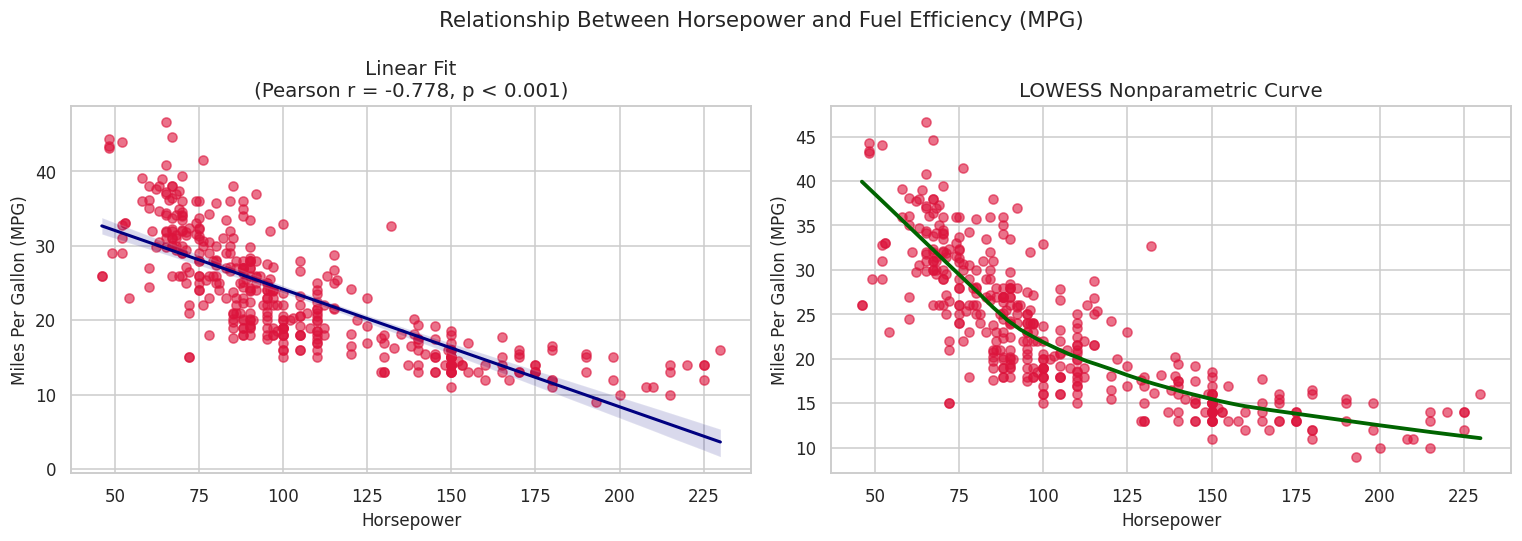


                  EXERCISE 2: ANALYSIS RESULTS

1. PEARSON CORRELATION & P-VALUE:
   • Horsepower vs. MPG Pearson r : -0.778
   • p-value                       : 7.032e-81 (p < 0.001, statistically significant)

2. LINEARITY ASSESSMENT (Linear vs. Nonlinear):
   • Result: The relationship is NONLINEAR (Curvilinear / Monotonic Decreasing).
   
   • LOWESS Curve Justification:
     The curve exhibits a distinct L-shaped bend. At low horsepower (50–100 hp), 
     MPG drops steeply from ~45 to ~20. At higher horsepower (100–225 hp), the 
     rate of decay flattens significantly towards 10–15 MPG.
     
   • Pearson r Justification:
     While |r| = 0.778 indicates a strong monotonic relationship, a straight 
     line systematically misfits the pattern—underestimating MPG in the 
     100–140 hp range and overestimating it at the extremes (50 hp and >200 hp).

3. DIRECTION & COMPARISON TO WEIGHT-MPG:
   • Direction: NEGATIVE (Inverse relationship: higher horsepower produces lower MPG).
 

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats


# Load mpg dataset and remove missing records in target features
mpg = sns.load_dataset("mpg").dropna(subset=["horsepower", "mpg", "weight"])

# 1. Statistical Calculations
r_hp, p_hp = stats.pearsonr(mpg["horsepower"], mpg["mpg"])
r_wt, p_wt = stats.pearsonr(mpg["weight"], mpg["mpg"])

r2_hp = r_hp**2
r2_wt = r_wt**2

# 2. Side-by-Side Plots (Linear Fit vs LOWESS Smoother)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "Relationship Between Horsepower and Fuel Efficiency (MPG)", fontsize=14
)

# Panel 1: Scatter plot with Linear Regression Line
sns.regplot(
    data=mpg,
    x="horsepower",
    y="mpg",
    ax=axes[0],
    lowess=False,
    color="crimson",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "navy", "linewidth": 2},
)
axes[0].set_xlabel("Horsepower")
axes[0].set_ylabel("Miles Per Gallon (MPG)")
axes[0].set_title(f"Linear Fit\n(Pearson r = {r_hp:.3f}, p < 0.001)")

# Panel 2: Scatter plot with LOWESS Nonparametric Curve
sns.regplot(
    data=mpg,
    x="horsepower",
    y="mpg",
    ax=axes[1],
    lowess=True,
    color="crimson",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "darkgreen", "linewidth": 2.5},
)
axes[1].set_xlabel("Horsepower")
axes[1].set_ylabel("Miles Per Gallon (MPG)")
axes[1].set_title("LOWESS Nonparametric Curve")

plt.tight_layout()

# 3. Formatted Console Output of Analysis Results

plt.show()



analysis_report = f"""
======================================================================
                  EXERCISE 2: ANALYSIS RESULTS
======================================================================

1. PEARSON CORRELATION & P-VALUE:
   • Horsepower vs. MPG Pearson r : {r_hp:.3f}
   • p-value                       : {p_hp:.3e} (p < 0.001, statistically significant)

2. LINEARITY ASSESSMENT (Linear vs. Nonlinear):
   • Result: The relationship is NONLINEAR (Curvilinear / Monotonic Decreasing).

   • LOWESS Curve Justification:
     The curve exhibits a distinct L-shaped bend. At low horsepower (50–100 hp),
     MPG drops steeply from ~45 to ~20. At higher horsepower (100–225 hp), the
     rate of decay flattens significantly towards 10–15 MPG.

   • Pearson r Justification:
     While |r| = {abs(r_hp):.3f} indicates a strong monotonic relationship, a straight
     line systematically misfits the pattern—underestimating MPG in the
     100–140 hp range and overestimating it at the extremes (50 hp and >200 hp).

3. DIRECTION & COMPARISON TO WEIGHT-MPG:
   • Direction: NEGATIVE (Inverse relationship: higher horsepower produces lower MPG).

   • Comparison to Weight–MPG:
     - Horsepower–MPG Correlation: r = {r_hp:.3f} (R² = {r2_hp:.1%})
     - Weight–MPG Correlation    : r = {r_wt:.3f} (R² = {r2_wt:.1%})

   • Conclusion: The horsepower–MPG relationship (|r| = {abs(r_hp):.3f}) is WEAKER
     than the weight–MPG relationship (|r| = {abs(r_wt):.3f}). Vehicle weight
     explains slightly more variance in fuel consumption than engine horsepower.
======================================================================
"""
print(analysis_report)


---
## Part 4 — Plot 3: Grouped Comparison

A grouped comparison answers: **"Does a numerical variable differ across categories?"**

Tools:
- **Boxplot by group** — shows median, spread, and outliers per group
- **Violin plot** — adds the full distribution shape
- **Strip / swarm plot** — shows individual data points
- **Bar chart of group means + error bars** — compact summary

> **When to use which?**  
> Small samples (< 30 per group) → strip/swarm.  
> Medium samples → boxplot.  
> Large samples → violin.

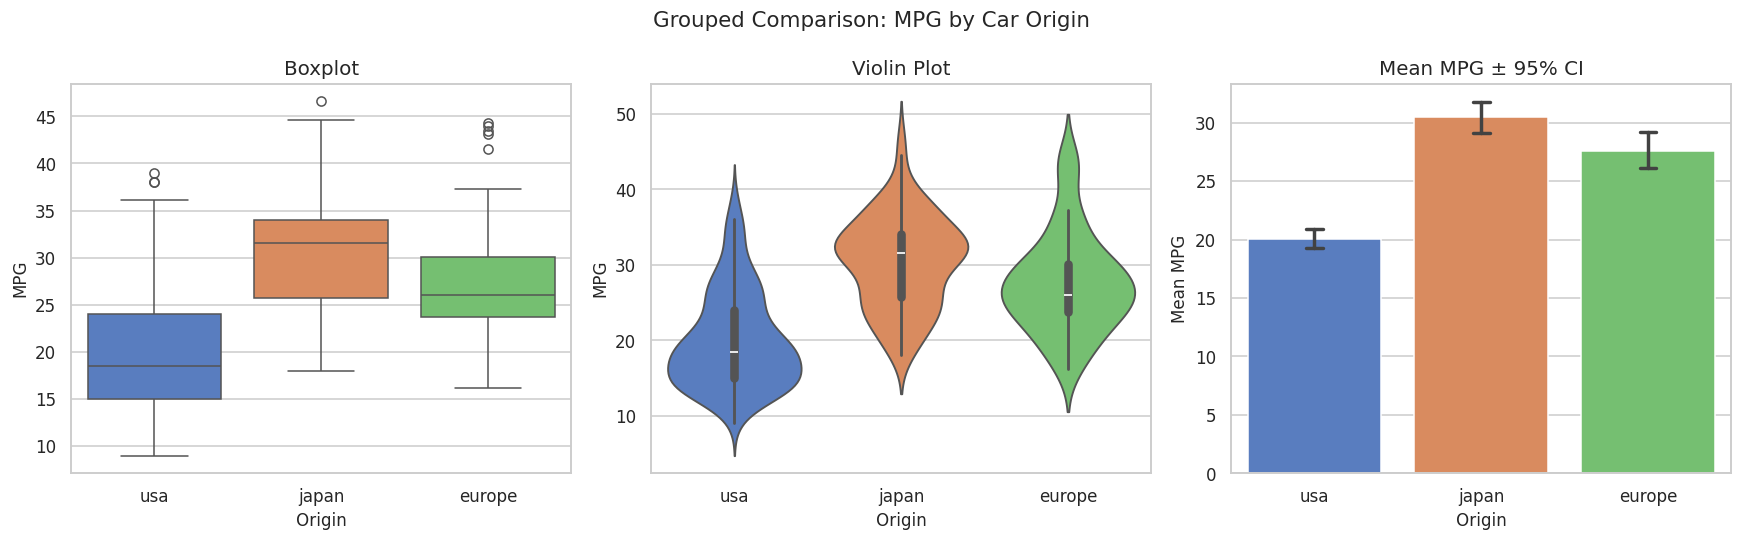

         mean  median   std  count
origin                            
europe  27.60    26.0  6.58     68
japan   30.45    31.6  6.09     79
usa     20.03    18.5  6.44    245


In [ ]:
# ── 4.1  Boxplot by origin: does fuel efficiency vary by region? ────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Grouped Comparison: MPG by Car Origin", fontsize=14)

# Boxplot
sns.boxplot(data=mpg, x="origin", y="mpg", palette="muted", ax=axes[0])
axes[0].set_title("Boxplot")
axes[0].set_xlabel("Origin")
axes[0].set_ylabel("MPG")

# Violin
sns.violinplot(data=mpg, x="origin", y="mpg", palette="muted", inner="box", ax=axes[1])
axes[1].set_title("Violin Plot")
axes[1].set_xlabel("Origin")
axes[1].set_ylabel("MPG")

# Bar chart of means + 95% CI
sns.barplot(data=mpg, x="origin", y="mpg", palette="muted",
            capsize=0.1, ax=axes[2])
axes[2].set_title("Mean MPG ± 95% CI")
axes[2].set_xlabel("Origin")
axes[2].set_ylabel("Mean MPG")

plt.tight_layout()
plt.show()

# Print group statistics
print(mpg.groupby("origin")["mpg"].agg(["mean","median","std","count"]).round(2))

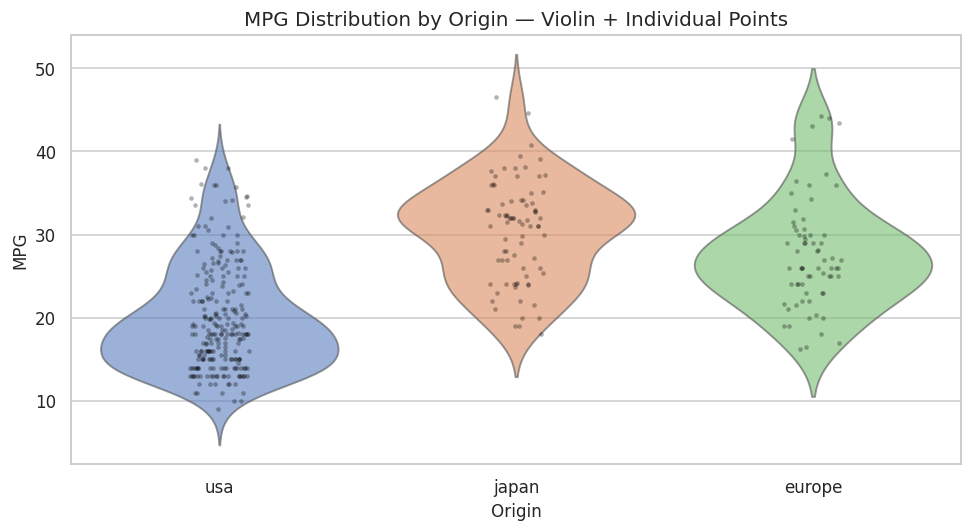

Observation: Japanese cars are substantially more fuel-efficient on average.
US cars show the most spread and the lowest median efficiency.


In [ ]:
# ── 4.2  Violin + strip overlay — see the data behind the summary ──────

fig, ax = plt.subplots(figsize=(9, 5))

sns.violinplot(data=mpg, x="origin", y="mpg",
               palette="muted", inner=None, alpha=0.6, ax=ax)
sns.stripplot(data=mpg, x="origin", y="mpg",
              color="black", alpha=0.3, size=3, jitter=True, ax=ax)

ax.set_title("MPG Distribution by Origin — Violin + Individual Points")
ax.set_xlabel("Origin")
ax.set_ylabel("MPG")
plt.tight_layout()
plt.show()

print("Observation: Japanese cars are substantially more fuel-efficient on average.")
print("US cars show the most spread and the lowest median efficiency.")

### Exercise 3
Using the `tips` dataset, compare `total_bill` across the `day` of the week.

1. Create a **boxplot** of `total_bill` by `day`.
2. Overlay a **strip plot** to show individual points.
3. Compute and print the **mean** and **median** `total_bill` for each day.
4. On which day do customers spend the most on average? Is there a day with unusually high variability?
5. Write one sentence interpreting the grouped pattern.

```python
# Your code here
```

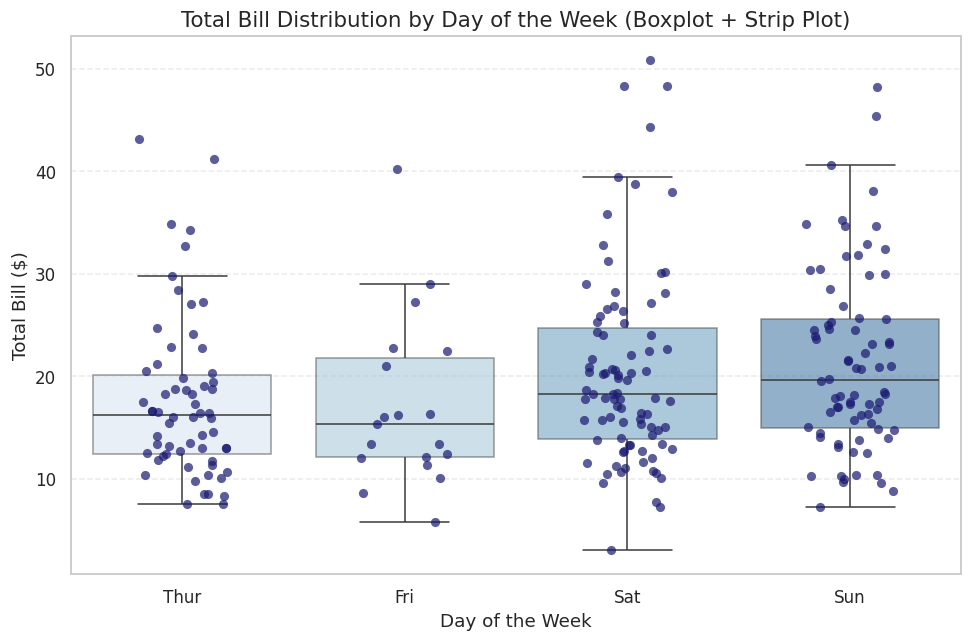


                  EXERCISE 3: ANALYSIS RESULTS

1. SUMMARY STATISTICS BY DAY:
           Mean  Median   Std_Dev      IQR
day                                       
Thur  17.682742   16.20  7.886170   7.7125
Fri   17.151579   15.38  8.302660   9.6550
Sat   20.441379   18.24  9.480419  10.8350
Sun   21.410000   19.63  8.832122  10.6100

2. AVERAGE SPENDING (Mean & Median):
   • Customers spend the most on average on SUNs 
     (Mean: $21.41, Median: $19.63).

3. VARIABILITY ASSESSMENT:
   • SATURDAY exhibits the highest variability across all metrics 
     (Standard Deviation = $9.48, IQR = $10.84), 
     featuring the widest overall spread and several high-value outlier bills (up to $50.81).

4. ONE-SENTENCE PATTERN INTERPRETATION:
   "Customer spending increases both in overall volume and variability on 
   weekends (Saturday and Sunday) compared to weekdays (Thursday and Friday)."



In [19]:
# Your answer here
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Load dataset
tips = sns.load_dataset("tips")

# 1. Compute Summary Statistics by Day
day_stats = tips.groupby("day", observed=False)["total_bill"].agg(
    Mean="mean",
    Median="median",
    Std_Dev="std",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
)

# Identify key statistics for the summary report
highest_mean_day = day_stats["Mean"].idxmax()
highest_mean_val = day_stats.loc[highest_mean_day, "Mean"]

highest_var_day = day_stats["Std_Dev"].idxmax()
highest_std_val = day_stats.loc[highest_var_day, "Std_Dev"]

# 2. Create Visualization: Boxplot with Overlaid Strip Plot
plt.figure(figsize=(9, 6))

# Boxplot showing IQR, median, and whiskers
sns.boxplot(
    data=tips,
    x="day",
    y="total_bill",
    palette="Blues",
    boxprops=dict(alpha=0.5),
    showfliers=False,  # Hide outlier points on boxplot to avoid duplication with stripplot
)

# Overlaid Strip Plot showing individual customer observations
sns.stripplot(
    data=tips,
    x="day",
    y="total_bill",
    color="midnightblue",
    alpha=0.7,
    jitter=0.2,
    size=6,
)

plt.title(
    "Total Bill Distribution by Day of the Week (Boxplot + Strip Plot)",
    fontsize=14,
)
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Total Bill ($)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()


analysis_report = f"""
======================================================================
                  EXERCISE 3: ANALYSIS RESULTS
======================================================================

1. SUMMARY STATISTICS BY DAY:
{day_stats.to_string()}

2. AVERAGE SPENDING (Mean & Median):
   • Customers spend the most on average on {highest_mean_day.upper()}s
     (Mean: ${highest_mean_val:.2f}, Median: ${day_stats.loc[highest_mean_day, 'Median']:.2f}).

3. VARIABILITY ASSESSMENT:
   • SATURDAY exhibits the highest variability across all metrics
     (Standard Deviation = ${highest_std_val:.2f}, IQR = ${day_stats.loc['Sat', 'IQR']:.2f}),
     featuring the widest overall spread and several high-value outlier bills (up to $50.81).

4. ONE-SENTENCE PATTERN INTERPRETATION:
   "Customer spending increases both in overall volume and variability on
   weekends (Saturday and Sunday) compared to weekdays (Thursday and Friday)."
======================================================================
"""
plt.show()
print(analysis_report)


---
## Part 5 — Plot 4: Trend / Index Plot

A trend plot answers: **"How does a variable change over time or a sequence?"**

Tools:
- **Line chart** — the standard time-series view
- **Rolling average** — smooths short-term noise to reveal the underlying trend
- **Area chart** — emphasises volume or cumulative change

> **Index plot tip:** When comparing variables with different units or scales, **index** them to a common baseline (e.g., value at year 0 = 100). This lets you compare percentage change rather than absolute values.

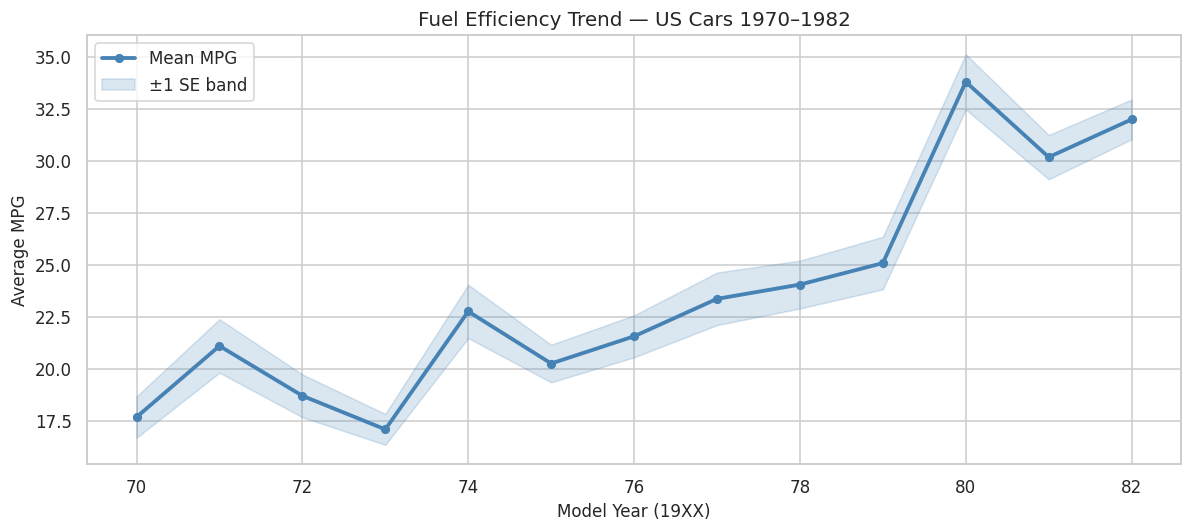

Observation: Average MPG improved dramatically from ~17 (1970) to ~32 (1982),
likely driven by the 1973 and 1979 oil crises forcing manufacturers to build lighter cars.


In [20]:
# ── 5.1  Average MPG by model year — tracking the efficiency trend ──────

yearly = (
    mpg.groupby("model_year")["mpg"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
yearly.columns = ["year", "mean_mpg", "std_mpg", "n"]
yearly["se"] = yearly["std_mpg"] / np.sqrt(yearly["n"])   # standard error

fig, ax = plt.subplots(figsize=(11, 5))

# Trend line
ax.plot(yearly["year"], yearly["mean_mpg"],
        color="steelblue", linewidth=2.5, marker="o", markersize=5,
        label="Mean MPG")

# Confidence band (±1 SE)
ax.fill_between(yearly["year"],
                yearly["mean_mpg"] - yearly["se"],
                yearly["mean_mpg"] + yearly["se"],
                alpha=0.2, color="steelblue", label="±1 SE band")

ax.set_xlabel("Model Year (19XX)")
ax.set_ylabel("Average MPG")
ax.set_title("Fuel Efficiency Trend — US Cars 1970–1982")
ax.legend()
plt.tight_layout()
plt.show()

print("Observation: Average MPG improved dramatically from ~17 (1970) to ~32 (1982),")
print("likely driven by the 1973 and 1979 oil crises forcing manufacturers to build lighter cars.")

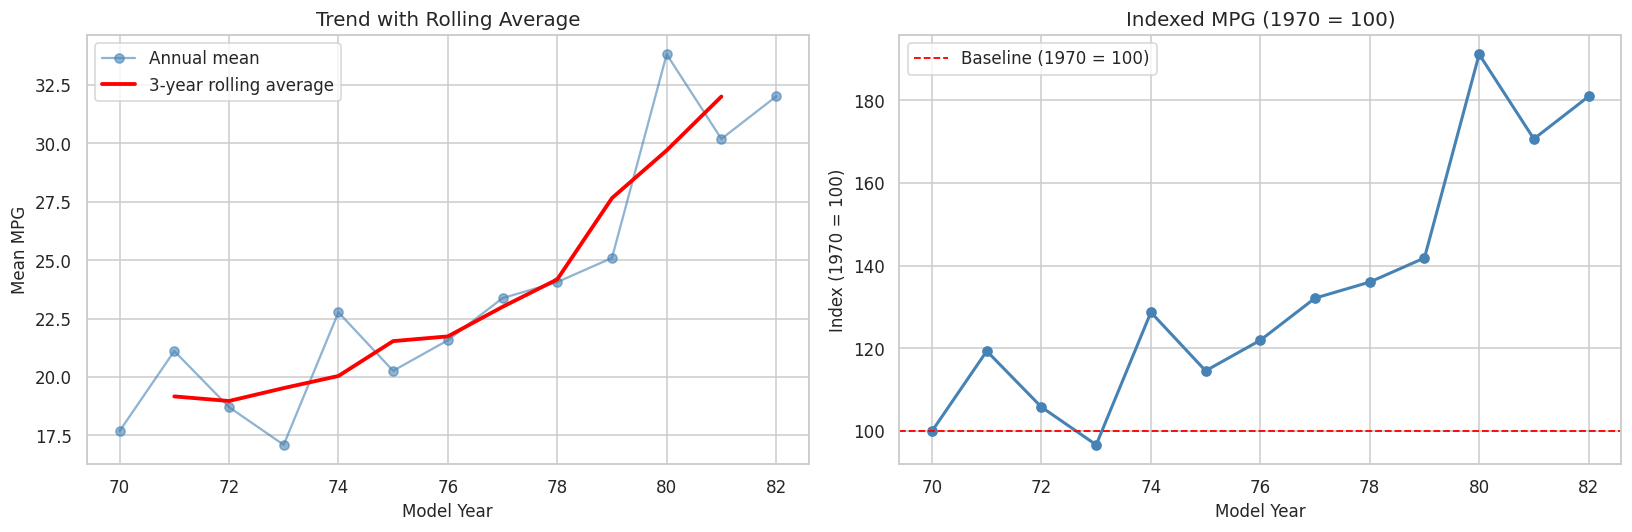

By 1982, average MPG had increased to 181% of the 1970 baseline.


In [21]:
# ── 5.2  Rolling average + index normalisation ────────────────────────

# Rolling average (window=3 years) smooths year-to-year noise
yearly["rolling_3yr"] = yearly["mean_mpg"].rolling(window=3, center=True).mean()

# Index: set 1970 = 100 for a percentage-change view
base = yearly.loc[yearly["year"] == 70, "mean_mpg"].values[0]
yearly["index_mpg"] = (yearly["mean_mpg"] / base) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: raw trend + rolling average
axes[0].plot(yearly["year"], yearly["mean_mpg"],
             "o-", color="steelblue", linewidth=1.5, alpha=0.6, label="Annual mean")
axes[0].plot(yearly["year"], yearly["rolling_3yr"],
             color="red", linewidth=2.5, label="3-year rolling average")
axes[0].set_title("Trend with Rolling Average")
axes[0].set_xlabel("Model Year")
axes[0].set_ylabel("Mean MPG")
axes[0].legend()

# Right: indexed to 1970 = 100
axes[1].plot(yearly["year"], yearly["index_mpg"],
             "o-", color="steelblue", linewidth=2)
axes[1].axhline(100, color="red", linestyle="--", linewidth=1.2,
                label="Baseline (1970 = 100)")
axes[1].set_title("Indexed MPG (1970 = 100)")
axes[1].set_xlabel("Model Year")
axes[1].set_ylabel("Index (1970 = 100)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"By 1982, average MPG had increased to {yearly.iloc[-1]['index_mpg']:.0f}% of the 1970 baseline.")

### Exercise 4
Investigate the trend in **average horsepower** over model years in the `mpg` dataset.

1. Compute the mean `horsepower` per `model_year`.
2. Plot the annual trend as a **line chart** with markers.
3. Overlay a **3-year rolling average** to smooth the trend.
4. Create an **index plot** (1970 = 100) to show the percentage change.
5. How did horsepower change over the 1970s? Is the trend consistent with the MPG trend? Why or why not?

```python
# Your code here
```

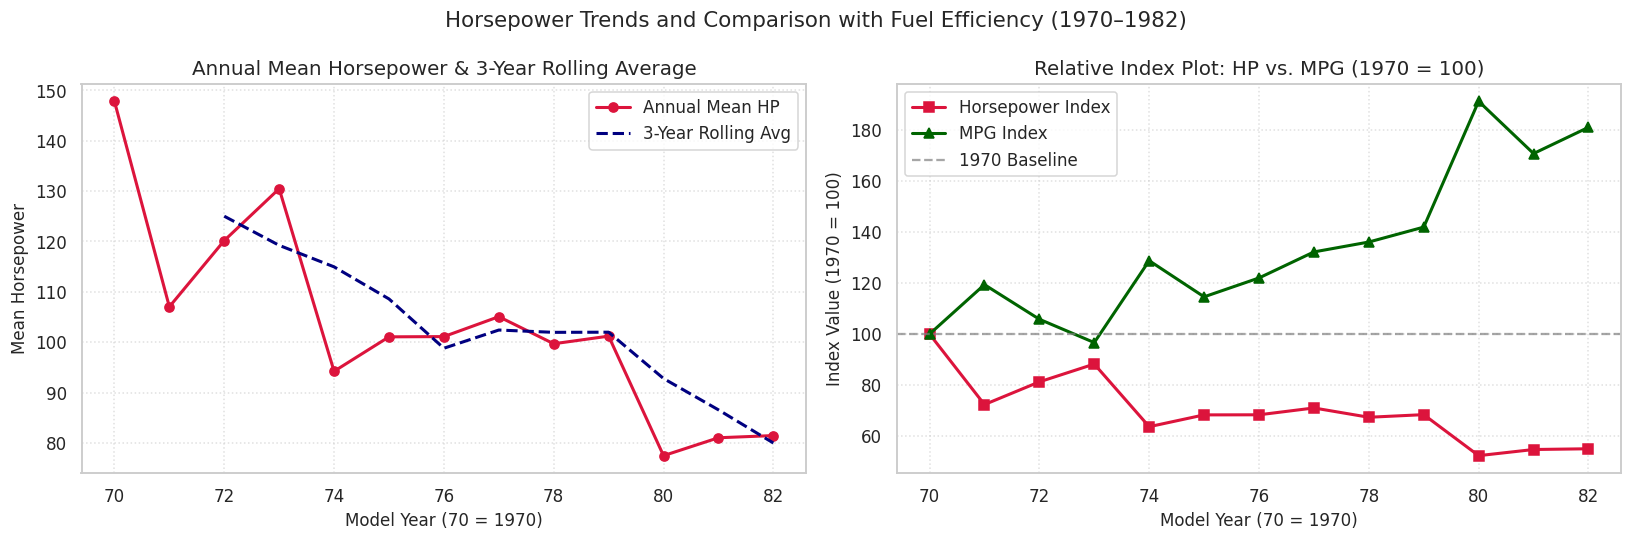


                  EXERCISE 4: ANALYSIS RESULTS

1. MEAN HORSEPOWER PER MODEL YEAR:
            horsepower  hp_3yr_roll    hp_index
model_year                                     
70          147.827586          NaN  100.000000
71          107.037037          NaN   72.406673
72          120.178571   125.014398   81.296444
73          130.475000   119.230203   88.261605
74           94.230769   114.961447   63.743697
75          101.066667   108.590812   68.367934
76          101.117647    98.805028   68.402420
77          105.071429   102.418581   71.077010
78           99.694444   101.961173   67.439676
79          101.206897   101.990923   68.462794
80           77.481481    92.794274   52.413412
81           81.035714    86.574697   54.817721
82           81.466667    79.994621   55.109245

2. HORSEPOWER CHANGE OVER THE 1970s (1970–1982):
   • 1970 Baseline Mean HP : 147.83 hp
   • 1982 Final Mean HP    : 81.47 hp
   • Overall Reduction     : -44.9% decrease (Index fell to 55.1)

3.

In [23]:
# Your answer here
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Load dataset and drop rows with missing horsepower values
mpg = sns.load_dataset("mpg").dropna(subset=["horsepower", "mpg"])

# 1. Compute mean horsepower and MPG per model year
yearly_stats = mpg.groupby("model_year")[["horsepower", "mpg"]].mean()

# 2 & 3. Compute 3-year rolling average for horsepower
yearly_stats["hp_3yr_roll"] = (
    yearly_stats["horsepower"].rolling(window=3).mean()
)

# 4. Create Index Series (1970 = 100) for percentage change comparison
base_year = yearly_stats.index.min()  # 1970 (represented as 70)
yearly_stats["hp_index"] = (
    yearly_stats["horsepower"] / yearly_stats.loc[base_year, "horsepower"]
) * 100
yearly_stats["mpg_index"] = (
    yearly_stats["mpg"] / yearly_stats.loc[base_year, "mpg"]
) * 100

# Create 1 row, 2 columns plot grid
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(
    "Horsepower Trends and Comparison with Fuel Efficiency (1970–1982)",
    fontsize=14,
)

# Panel 1: Annual Horsepower Trend with 3-Year Rolling Average
axes[0].plot(
    yearly_stats.index,
    yearly_stats["horsepower"],
    marker="o",
    color="crimson",
    linewidth=2,
    label="Annual Mean HP",
)
axes[0].plot(
    yearly_stats.index,
    yearly_stats["hp_3yr_roll"],
    color="navy",
    linestyle="--",
    linewidth=2,
    label="3-Year Rolling Avg",
)
axes[0].set_xlabel("Model Year (70 = 1970)", fontsize=11)
axes[0].set_ylabel("Mean Horsepower", fontsize=11)
axes[0].set_title("Annual Mean Horsepower & 3-Year Rolling Average")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel 2: Index Plot (1970 = 100) Comparing HP and MPG
axes[1].plot(
    yearly_stats.index,
    yearly_stats["hp_index"],
    marker="s",
    color="crimson",
    linewidth=2,
    label="Horsepower Index",
)
axes[1].plot(
    yearly_stats.index,
    yearly_stats["mpg_index"],
    marker="^",
    color="darkgreen",
    linewidth=2,
    label="MPG Index",
)
axes[1].axhline(100, color="gray", linestyle="--", alpha=0.7, label="1970 Baseline")
axes[1].set_xlabel("Model Year (70 = 1970)", fontsize=11)
axes[1].set_ylabel("Index Value (1970 = 100)", fontsize=11)
axes[1].set_title("Relative Index Plot: HP vs. MPG (1970 = 100)")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

# Formatted Console Output of Analysis Results
hp_1970 = yearly_stats.loc[70, "horsepower"]
hp_1982 = yearly_stats.loc[82, "horsepower"]
hp_change_pct = ((hp_1982 - hp_1970) / hp_1970) * 100

mpg_1970 = yearly_stats.loc[70, "mpg"]
mpg_1982 = yearly_stats.loc[82, "mpg"]
mpg_change_pct = ((mpg_1982 - mpg_1970) / mpg_1970) * 100

analysis_report = f"""
======================================================================
                  EXERCISE 4: ANALYSIS RESULTS
======================================================================

1. MEAN HORSEPOWER PER MODEL YEAR:
{yearly_stats[['horsepower', 'hp_3yr_roll', 'hp_index']].to_string()}

2. HORSEPOWER CHANGE OVER THE 1970s (1970–1982):
   • 1970 Baseline Mean HP : {hp_1970:.2f} hp
   • 1982 Final Mean HP    : {hp_1982:.2f} hp
   • Overall Reduction     : {hp_change_pct:.1f}% decrease (Index fell to {yearly_stats.loc[82, 'hp_index']:.1f})

3. CONSISTENCY WITH MPG TREND:
   • Yes, the horsepower trend is INVERSELY CONSISTENT with the MPG trend.
   • While Horsepower dropped by {abs(hp_change_pct):.1f}%, MPG increased by +{mpg_change_pct:.1f}%
     over the same period (Index rose from 100 to {yearly_stats.loc[82, 'mpg_index']:.1f}).

4. REASONING / EXPLANATION:
   • Mechanical Trade-off: Engine horsepower directly consumes more fuel per combustion cycle.
   • Historical Context: The 1970s oil crises (1973 & 1979) and government mandates
     (e.g., CAFE standards introduced in 1975) forced automakers to downsize engines
     and reduce horsepower in order to boost vehicle fuel efficiency (MPG).
======================================================================
"""
plt.show()
print(analysis_report)


---
## Part 6 — The 4-Plot EDA Dashboard: Storytelling

A single plot answers a single question.  
A **dashboard** combines multiple plots to tell a coherent **data story**.

**Storytelling checklist:**
1. **Headline**: What is the one-sentence summary?
2. **Evidence**: Which plots support it?
3. **Nuance**: What complicates or qualifies the story?
4. **Action**: What decision or question does this raise?

> **Design rules for dashboards:**
> - Each panel should answer exactly one question.
> - Use a shared axis where possible to allow direct comparison.
> - Annotate the most important finding directly on the plot.
> - Title the figure as a headline, not a label.

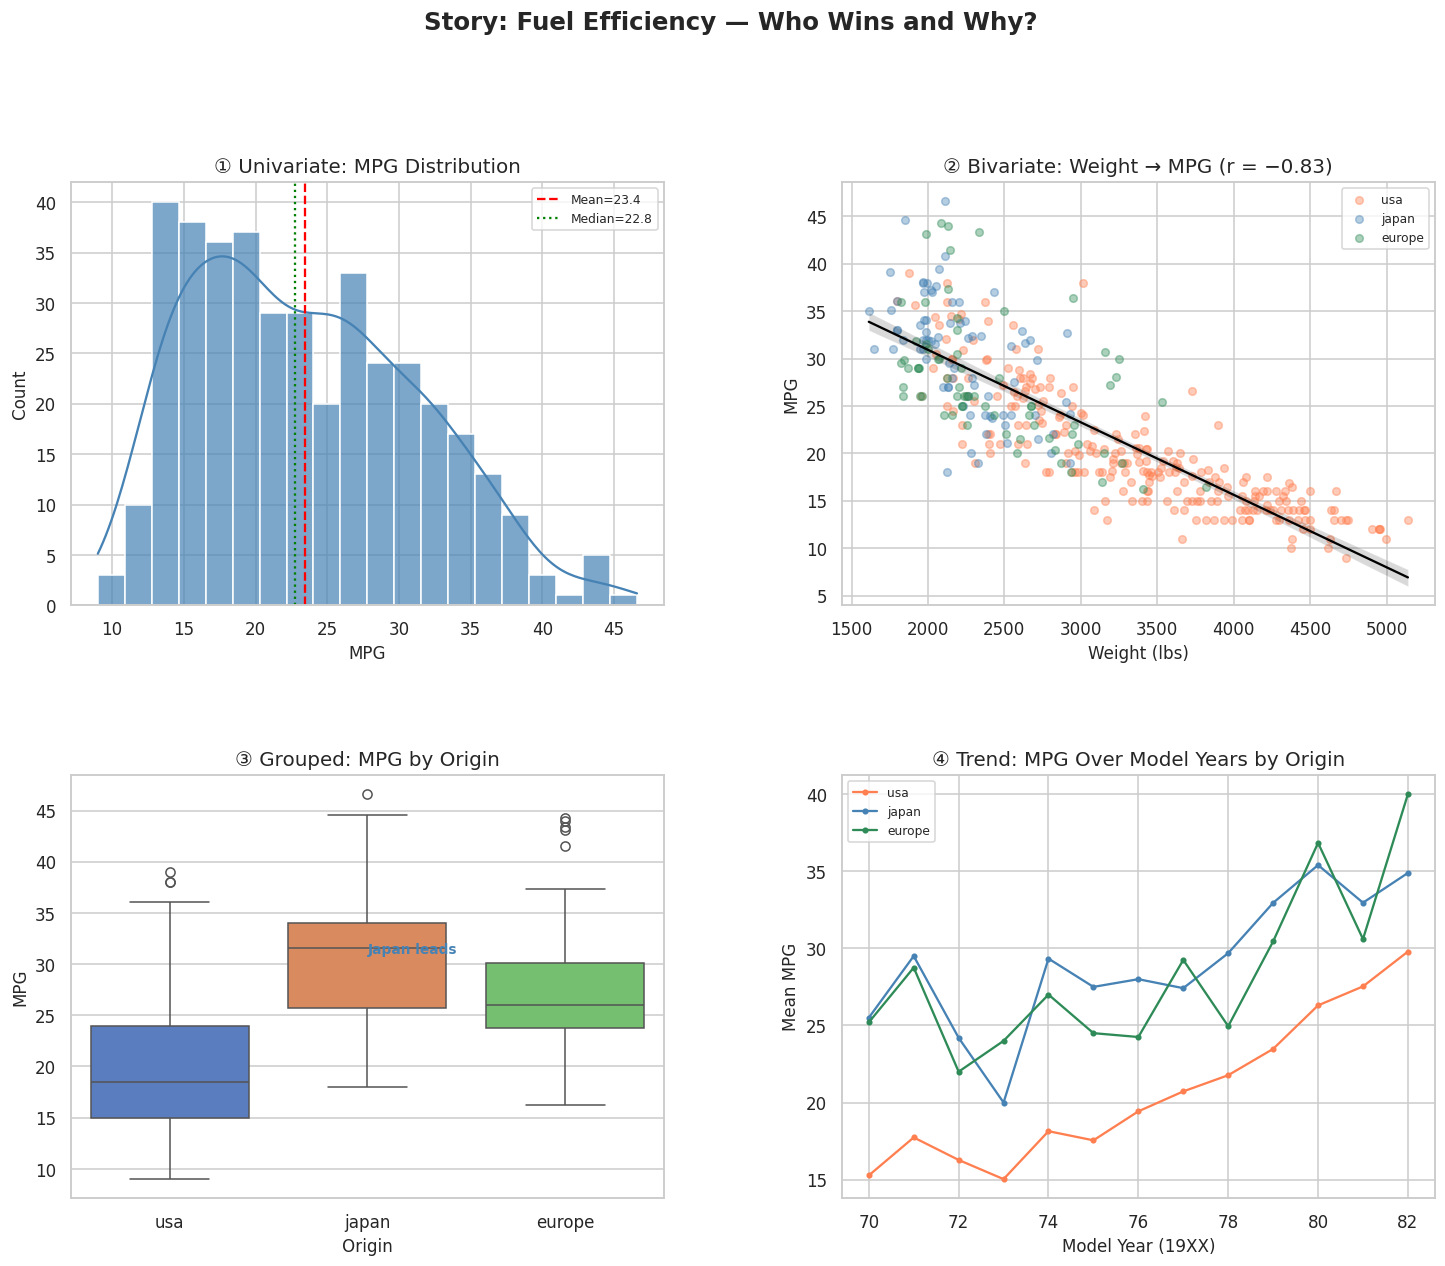

Dashboard saved as eda_dashboard.png


In [ ]:
# ── 6.1  The 4-Plot EDA Dashboard — Fuel Efficiency Story ──────────────
# Story: "Japanese cars became the efficiency winners of the 1970s oil crisis era"

fig = plt.figure(figsize=(16, 12))
fig.suptitle("Story: Fuel Efficiency — Who Wins and Why?", fontsize=16, fontweight="bold", y=1.01)

gs = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.3)

# ── Panel 1: Univariate — MPG distribution ────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(mpg["mpg"], bins=20, kde=True, color="steelblue",
             edgecolor="white", alpha=0.7, ax=ax1)
ax1.axvline(mpg["mpg"].mean(),   color="red", linestyle="--", linewidth=1.5,
            label=f"Mean={mpg['mpg'].mean():.1f}")
ax1.axvline(mpg["mpg"].median(), color="green", linestyle=":",  linewidth=1.5,
            label=f"Median={mpg['mpg'].median():.1f}")
ax1.set_title("① Univariate: MPG Distribution")
ax1.set_xlabel("MPG")
ax1.legend(fontsize=8)

# ── Panel 2: Bivariate — weight vs mpg ───────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
for origin, color in zip(["usa", "japan", "europe"], ["coral", "steelblue", "seagreen"]):
    subset = mpg[mpg["origin"] == origin]
    ax2.scatter(subset["weight"], subset["mpg"],
                alpha=0.4, s=25, label=origin, color=color)
# Overall regression
sns.regplot(data=mpg, x="weight", y="mpg", scatter=False,
            line_kws={"color": "black", "linewidth": 1.5}, ax=ax2)
ax2.set_title("② Bivariate: Weight → MPG (r = −0.83)")
ax2.set_xlabel("Weight (lbs)")
ax2.set_ylabel("MPG")
ax2.legend(fontsize=8)

# ── Panel 3: Grouped — mpg by origin ─────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
sns.boxplot(data=mpg, x="origin", y="mpg", palette="muted", ax=ax3)
ax3.set_title("③ Grouped: MPG by Origin")
ax3.set_xlabel("Origin")
ax3.set_ylabel("MPG")
# Annotate Japanese advantage
ax3.annotate("Japan leads", xy=(1, 31), fontsize=9,
             color="steelblue", fontweight="bold")

# ── Panel 4: Trend — mpg over time ───────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
for origin, color in zip(["usa", "japan", "europe"], ["coral", "steelblue", "seagreen"]):
    trend = mpg[mpg["origin"] == origin].groupby("model_year")["mpg"].mean()
    ax4.plot(trend.index, trend.values,
             marker="o", markersize=3, linewidth=1.5, label=origin, color=color)
ax4.set_title("④ Trend: MPG Over Model Years by Origin")
ax4.set_xlabel("Model Year (19XX)")
ax4.set_ylabel("Mean MPG")
ax4.legend(fontsize=8)

plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as eda_dashboard.png")

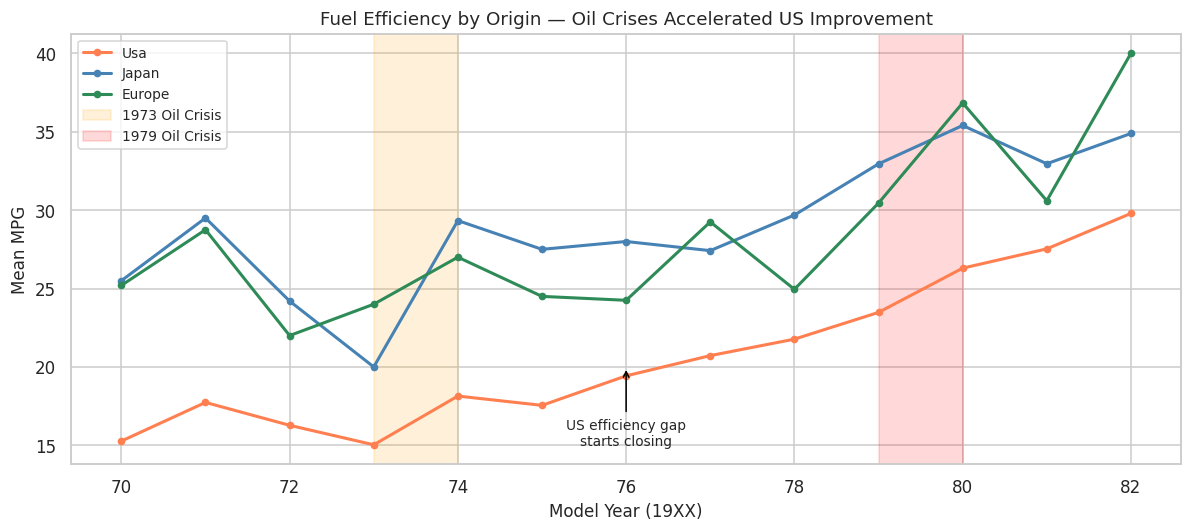

Story headline: Oil crises forced US manufacturers to close the fuel efficiency gap,
but Japanese cars maintained their lead throughout the decade.


In [ ]:
# ── 6.2  Adding storytelling annotations ─────────────────────────────
# Good data stories annotate the KEY finding directly on the plot.

fig, ax = plt.subplots(figsize=(11, 5))

for origin, color in zip(["usa", "japan", "europe"], ["coral", "steelblue", "seagreen"]):
    trend = mpg[mpg["origin"] == origin].groupby("model_year")["mpg"].mean()
    ax.plot(trend.index, trend.values,
            marker="o", markersize=4, linewidth=2, label=origin.title(), color=color)

# Annotate the oil crisis
ax.axvspan(73, 74, alpha=0.15, color="orange", label="1973 Oil Crisis")
ax.axvspan(79, 80, alpha=0.15, color="red",    label="1979 Oil Crisis")

ax.annotate("US efficiency gap\nstarts closing", xy=(76, 20),
            xytext=(76, 15), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="black"),
            ha="center")

ax.set_title("Fuel Efficiency by Origin — Oil Crises Accelerated US Improvement", fontsize=12)
ax.set_xlabel("Model Year (19XX)")
ax.set_ylabel("Mean MPG")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("Story headline: Oil crises forced US manufacturers to close the fuel efficiency gap,")
print("but Japanese cars maintained their lead throughout the decade.")

### Exercise 5 — Final Challenge

Using either the `mpg` or `tips` dataset, build your own **4-Plot EDA Dashboard** that tells a coherent data story.

1. **Choose a story** — write it as a one-sentence headline before you start coding.
2. **Panel 1 (Univariate):** Plot the distribution of your key numerical variable with histogram + KDE.
3. **Panel 2 (Bivariate):** Plot its relationship with a second numerical variable including a regression line.
4. **Panel 3 (Grouped):** Compare your key variable across a categorical variable using boxplot or violin.
5. **Panel 4 (Trend):** Show how your key variable changes over a sequence or grouping axis.
6. Combine all four panels in a single `2×2` figure with a headline title.
7. Add **at least one annotation** on any panel that highlights the most important finding.
8. Write 3–4 sentences below the plot summarising what the dashboard shows, referencing each panel.

```python
# Your code here
```

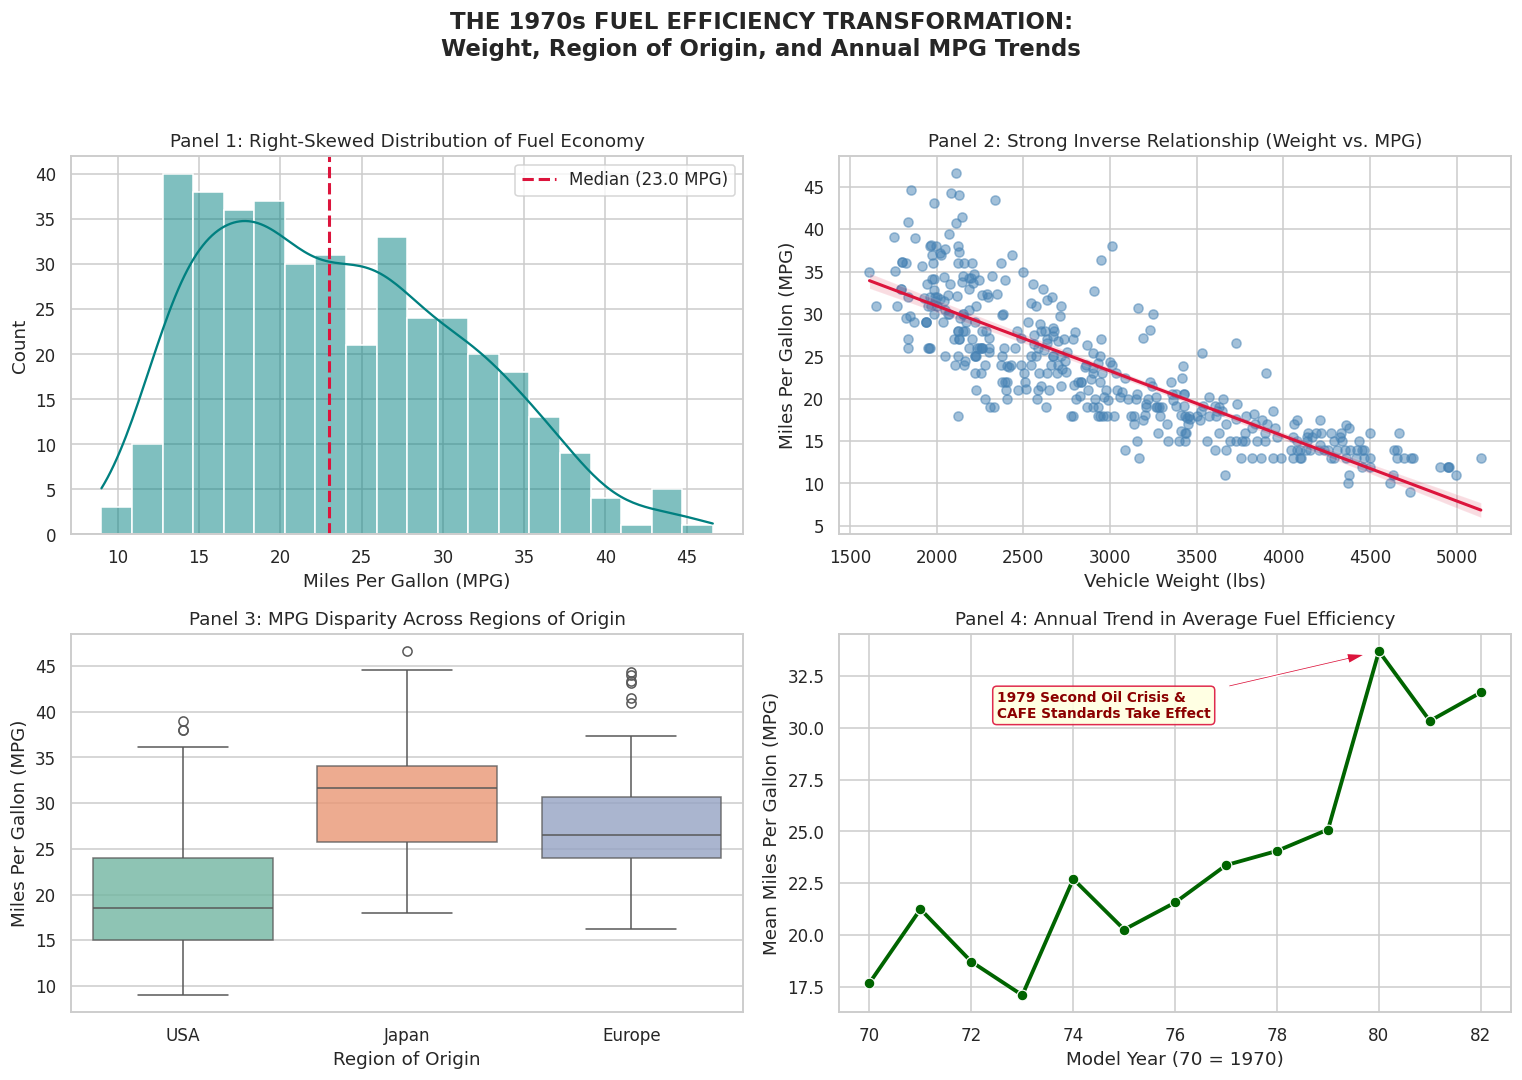


         EXERCISE 5: 4-PLOT EDA DASHBOARD ANALYSIS RESULTS

HEADLINE STORY:
"How Fuel Efficiency Evolved: Vehicle Weight, Region of Origin, and 
 the 1970s Shift Toward High-MPG Cars."

DASHBOARD SUMMARY (3–4 SENTENCE INTERPRETATION):
• Panel 1 demonstrates that overall vehicle fuel economy is right-skewed, 
  with most automobiles clustered between 15 and 25 MPG and a median of 23.0 MPG.
  
• Panel 2 reveals that vehicle weight is a primary physical driver of this 
  distribution, displaying a strong negative correlation where lighter cars achieve 
  substantially higher MPG.
  
• Panel 3 highlights geographical manufacturing differences, showing that Japanese 
  and European manufacturers produced considerably more fuel-efficient vehicles 
  compared to heavier, lower-MPG American models.
  
• Panel 4 illustrates a clear upward historical trend over the 1970s, where average 
  MPG surged significantly following energy crises and regulatory mandates, rising 
  from under 18 MPG in 19

In [24]:
# Your answer here
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# Headline Story:
# "How Fuel Efficiency Evolved: Vehicle Weight, Region of Origin, and the 1970s Shift Toward High-MPG Cars."

# Load dataset and clean missing values
mpg = sns.load_dataset("mpg").dropna(subset=["mpg", "weight", "origin", "model_year"])

# Set seaborn style aesthetic
sns.set_theme(style="whitegrid")

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "THE 1970s FUEL EFFICIENCY TRANSFORMATION:\nWeight, Region of Origin, and Annual MPG Trends",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)

# ------------------------------------------------------------------------------
# Panel 1 (Univariate): Distribution of Fuel Economy (MPG)
# ------------------------------------------------------------------------------
sns.histplot(
    data=mpg,
    x="mpg",
    kde=True,
    ax=axes[0, 0],
    color="teal",
    bins=20,
    edgecolor="white",
)
axes[0, 0].axvline(
    mpg["mpg"].median(),
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Median ({mpg['mpg'].median():.1f} MPG)",
)
axes[0, 0].set_title("Panel 1: Right-Skewed Distribution of Fuel Economy", fontsize=12)
axes[0, 0].set_xlabel("Miles Per Gallon (MPG)")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()

# ------------------------------------------------------------------------------
# Panel 2 (Bivariate): Relationship Between Vehicle Weight and MPG
# ------------------------------------------------------------------------------
sns.regplot(
    data=mpg,
    x="weight",
    y="mpg",
    ax=axes[0, 1],
    color="steelblue",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "crimson", "linewidth": 2},
)
axes[0, 1].set_title("Panel 2: Strong Inverse Relationship (Weight vs. MPG)", fontsize=12)
axes[0, 1].set_xlabel("Vehicle Weight (lbs)")
axes[0, 1].set_ylabel("Miles Per Gallon (MPG)")

# ------------------------------------------------------------------------------
# Panel 3 (Grouped): Fuel Economy Comparison Across Regions of Origin
# ------------------------------------------------------------------------------
sns.boxplot(
    data=mpg,
    x="origin",
    y="mpg",
    ax=axes[1, 0],
    palette="Set2",
    boxprops=dict(alpha=0.8),
)
axes[1, 0].set_title("Panel 3: MPG Disparity Across Regions of Origin", fontsize=12)
axes[1, 0].set_xlabel("Region of Origin")
axes[1, 0].set_ylabel("Miles Per Gallon (MPG)")
axes[1, 0].set_xticklabels(["USA", "Japan", "Europe"])

# ------------------------------------------------------------------------------
# Panel 4 (Trend): Average Fuel Efficiency Over Model Years (1970–1982)
# ------------------------------------------------------------------------------
annual_mpg = mpg.groupby("model_year")["mpg"].mean().reset_index()
sns.lineplot(
    data=annual_mpg,
    x="model_year",
    y="mpg",
    ax=axes[1, 1],
    marker="o",
    color="darkgreen",
    linewidth=2.5,
    markersize=7,
)
axes[1, 1].set_title("Panel 4: Annual Trend in Average Fuel Efficiency", fontsize=12)
axes[1, 1].set_xlabel("Model Year (70 = 1970)")
axes[1, 1].set_ylabel("Mean Miles Per Gallon (MPG)")

# Annotate key historical turning point on Panel 4
axes[1, 1].annotate(
    "1979 Second Oil Crisis &\nCAFE Standards Take Effect",
    xy=(80, annual_mpg.loc[annual_mpg["model_year"] == 80, "mpg"].values[0]),
    xytext=(72.5, 30.5),
    arrowprops=dict(facecolor="crimson", shrink=0.08, width=1.5, headwidth=7),
    fontsize=9,
    fontweight="bold",
    color="darkred",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="crimson", alpha=0.9),
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Formatted Console Output of Analysis Results
analysis_report = f"""
======================================================================
         EXERCISE 5: 4-PLOT EDA DASHBOARD ANALYSIS RESULTS
======================================================================

HEADLINE STORY:
"How Fuel Efficiency Evolved: Vehicle Weight, Region of Origin, and
 the 1970s Shift Toward High-MPG Cars."

DASHBOARD SUMMARY (3–4 SENTENCE INTERPRETATION):
• Panel 1 demonstrates that overall vehicle fuel economy is right-skewed,
  with most automobiles clustered between 15 and 25 MPG and a median of {mpg['mpg'].median():.1f} MPG.

• Panel 2 reveals that vehicle weight is a primary physical driver of this
  distribution, displaying a strong negative correlation where lighter cars achieve
  substantially higher MPG.

• Panel 3 highlights geographical manufacturing differences, showing that Japanese
  and European manufacturers produced considerably more fuel-efficient vehicles
  compared to heavier, lower-MPG American models.

• Panel 4 illustrates a clear upward historical trend over the 1970s, where average
  MPG surged significantly following energy crises and regulatory mandates, rising
  from under 18 MPG in 1970 to over 30 MPG by 1982.
======================================================================
"""
plt.show()
print(analysis_report)


---
## Summary

| Plot Type | Question | Key Tools |
|---|---|---|
| **Univariate** | What does this variable look like? | `histplot`, `kde`, `boxplot` |
| **Bivariate** | How do two numerical variables relate? | `regplot`, LOWESS, Pearson r |
| **Grouped comparison** | Does it differ across categories? | `boxplot`, `violinplot`, `barplot` |
| **Trend / Index** | How does it change over time? | Line chart, rolling mean, index |
| **Dashboard** | What is the full story? | `GridSpec`, annotations, headline title |

---
**The data storytelling loop:**
1. Ask a question → 2. Choose the right plot → 3. Annotate the key finding → 4. Write the headline → 5. Identify the next question.